In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import ToTensor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Handling the dataset

In [2]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor() # scaling the pixel values from 0 -> 255 to 0 -> 1
)

print(len(training_data))

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

print(len(test_data))

60000
10000


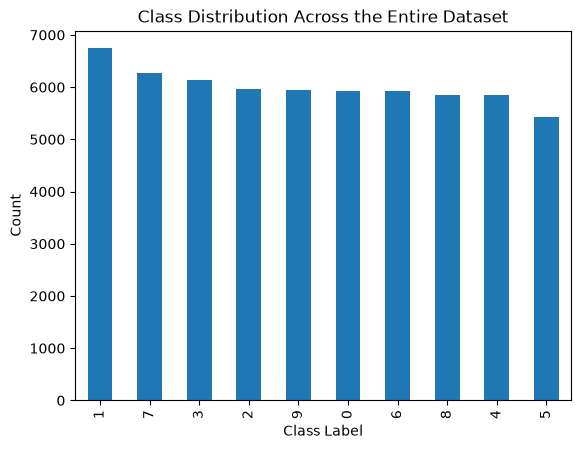

In [3]:
all_labels = []

for _, labels in training_data:
    all_labels.append(labels)

pd.Series(all_labels).value_counts().plot(kind="bar")
plt.title("Class Distribution Across the Entire Dataset")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

In [4]:
# This prints each digit and its exact count
counts = pd.Series(all_labels).value_counts()
print(counts)

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64


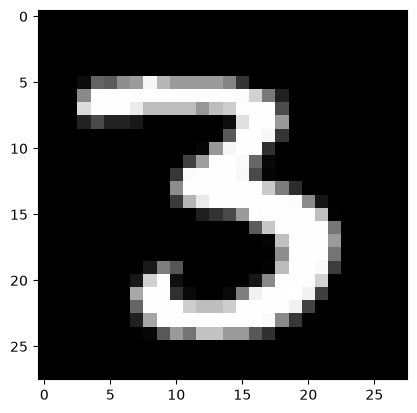

In [5]:
image_three, label_three = training_data[12]
image = image_three.unsqueeze(0)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

### Make the data for each client non-IID
- client1 - more data consisting of 0,1,2,3
- client2 - more data consisting of 4,5,6
- client3 - more data consisting of 7,8,9

Using **Dirichlet distribution**:
Dirichlet distribution is a standard method in machine learning, especially in Federated Learning (FL), to partition a centralized dataset into non-IID (non-independent and identically distributed) client splits

In [6]:
client1_train_data, client2_train_data, client3_train_data = random_split(
    training_data,
    [20000,20000,20000]
)

print(len(client1_train_data))
print(len(client2_train_data))
print(len(client3_train_data))

20000
20000
20000


In [7]:
client1_test_data, client2_test_data, client3_test_data = random_split(
    test_data,
    [3333,3333,3334]
)

print(len(client1_test_data))
print(len(client2_test_data))
print(len(client3_test_data))

3333
3333
3334


In [8]:
# dataloader
def create_dataloaders(train_data, test_data):
    train_data_loader = DataLoader(
        train_data,
        batch_size=64,
        shuffle=True
    )

    test_data_loader = DataLoader(
        test_data,
        batch_size=64,
        shuffle=True
    )

    return train_data_loader, test_data_loader

In [9]:
client1_train_loader, client1_test_loader = create_dataloaders (
    client1_train_data,
    client1_test_data
)

client2_train_loader, client2_test_loader = create_dataloaders (
    client2_train_data,
    client2_test_data
)

client3_train_loader, client3_test_loader = create_dataloaders (
    client3_train_data,
    client3_test_data
)

In [10]:
images, labels = next(iter(client1_train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        # flatten layer
        # self.flatten = nn.flatten() # input [1,28,28] flattened input 1x28x28 = 784
        
        # define linear layers
        self.fcl1 = nn.Linear(784,128)
        self.fcl2 = nn.Linear(128,64)
        self.fcl3 = nn.Linear(64, 10)

    def forward(self,x):
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

### Minimal Federated learning model
without using flower 

In [61]:
global_model = MLP()

client1_model = MLP()
client2_model = MLP()
client3_model = MLP()

In [62]:
# ensure the clients start with the same weights as the global model
client1_model.load_state_dict(global_model.state_dict())
client2_model.load_state_dict(global_model.state_dict())
client3_model.load_state_dict(global_model.state_dict())

<All keys matched successfully>

In [63]:
loss_function = nn.CrossEntropyLoss() 

# define each models own optimiser 
client1_optimiser = optim.Adam(
    client1_model.parameters(), 
    lr=0.005
)

client2_optimiser = optim.Adam(
    client2_model.parameters(), 
    lr=0.001
)

client3_optimiser = optim.Adam(
    client3_model.parameters(), 
    lr=0.001
)

In [70]:
def train_client(epochs, client, loader, loss_function, optimiser, model):
    for epoch in range(epochs):
        print(f"{client}: Starting training for epoch {epoch} ...")
    
        running_loss = 0.0
    
        for index, data in enumerate(loader):
            inputs, label = data
    
            optimiser.zero_grad()
            
            outputs = model(inputs)
    
            loss = loss_function(outputs, label)
            loss.backward()
            optimiser.step()
    
            running_loss += loss.item()
    
        print(f'{client}:Loss: {running_loss / len(loader):.4f}')
    return model
        
    #torch.save(model.state_dict(), f'trained_{client}_mlp.pth')

In [71]:
client1_model = train_client(3, "client 1", client1_train_loader, loss_function, client1_optimiser, client1_model)

client 1: Starting training for epoch 0 ...
client 1:Loss: 0.3754
client 1: Starting training for epoch 1 ...
client 1:Loss: 0.1636
client 1: Starting training for epoch 2 ...
client 1:Loss: 0.1080


In [72]:
client2_model = train_client(3, "client 2", client2_train_loader, loss_function, client2_optimiser, client2_model)

client 2: Starting training for epoch 0 ...
client 2:Loss: 0.5635
client 2: Starting training for epoch 1 ...
client 2:Loss: 0.2504
client 2: Starting training for epoch 2 ...
client 2:Loss: 0.1814


In [73]:
client3_model = train_client(3, "client 3", client3_train_loader, loss_function, client3_optimiser, client3_model)

client 3: Starting training for epoch 0 ...
client 3:Loss: 0.1413
client 3: Starting training for epoch 1 ...
client 3:Loss: 0.1135
client 3: Starting training for epoch 2 ...
client 3:Loss: 0.0891


In [74]:
def test_client(client, model, loader):
    # test the model
    correct = 0
    total = 0
    
    with torch.no_grad():
        for index, data in enumerate(loader):
            inputs, label = data
    
            outputs = model(inputs)
    
            _, predicted = torch.max(outputs, 1)
            total += label.size(0)
    
            correct += (predicted == label).sum().item()
    
    accuracy = 100* correct / total
    
    print(f'{client} test accuracy: {accuracy}%')
    return accuracy

In [ ]:
client1_test = test_client("client 1", client1_model, client1_test_loader)

In [ ]:
client2_test = test_client("client 2", client2_model, client2_test_loader)

In [ ]:
client3_test = test_client("client 3", client3_model, client3_test_loader)